# QFIM-Based Operator Selection for CS-VQE

**Qiskit Fall Fest 2026 | Quantum Chemistry (Intermediate)**

**Team:** Yi Liu, Lyuna Niemet

Zheng et al. developed a CS-VQE-SQD pipeline that reduces the quantum circuit before recovering molecular energies through sampled subspace diagonalization [1, 2]. For HCl, they report a 590× runtime speedup over conventional full-space VQE, with the register reduced from 20 to 3 qubits [1, Section 4.2].

We wanted to see whether the remaining variational circuit could be reduced further without losing chemical accuracy in ideal simulation. Our addition investigates an alternative to the paper's gradient-based operator ranking with a multi-point quantum Fisher information matrix (QFIM) selection criterion, and compares it with gradient ranking and random subsets.

For HCl (STO-3G), the QFIM-selected ansatz retains **4 of 16 excitation operators** and reaches **0.966 mHa VQE error**, below the 1.6 mHa chemical-accuracy threshold.

## From the molecular Hamiltonian to a smaller variational circuit

The goal is to approximate the ground-state energy of HCl. In conventional VQE, we represent the electronic Hamiltonian using qubits, then optimize a parameterized circuit to find a state with the lowest possible expectation value of energy. For HCl, the original representation requires 20 qubits.

Contextual-subspace VQE reduces the number of qubits by treating part of the Hamiltonian classically and keeping the remaining quantum correlations in a smaller subspace. This reduces the HCl problem to 3 qubits, although restricting the Hamiltonian to this subspace also introduces some error relative to the full ground-state energy.

Reducing the number of qubits does not necessarily mean the variational circuit is simple. We still need excitation operators to generate different possible states from the initial Hartree-Fock state. Keeping all of them makes the circuit deeper, but removing operators also restricts which states the circuit can reach.

We therefore investigate whether some operators can be removed without significantly affecting the VQE energy. Instead of ranking them by their initial energy gradients, we use the QFIM to examine how each parameter changes the quantum state and how much these changes overlap. The idea is to retain operators that provide different directions for the state to vary, rather than several operators that have similar effects.

## QFIM-based operator selection

We use the QFIM to describe how the quantum state changes as the variational parameters change [3]. Since these changes depend on the parameter values, we calculate the QFIM at eight different points and average the results: the zero vector and seven randomly sampled parameter vectors.

$$
\overline F=\frac18\sum_{k=1}^{8}F(\boldsymbol\theta^{(k)}).
$$

We then select four operators by greedily maximizing the regularized log-determinant of the corresponding QFIM submatrix:

$$
S_{t+1}=S_t\cup\left\{\underset{i\notin S_t}{\arg\max}\;\log\det\left(\overline F_{S_t\cup\{i\}}+10^{-8}I\right)\right\}.
$$

The determinant favors parameter directions that change the quantum state substantially without overlapping too much. We select one operator at a time, keeping the previous choices fixed. This does not guarantee the lowest possible VQE energy, so we compare the result against gradient-based selection and ten random subsets, all retaining four operators.

For the simulation benchmarks, we use ideal statevector simulation with zero initialization and COBYLA optimization (up to 500 function evaluations). We compare VQE errors relative to the full configuration interaction (FCI) energy to evaluate the selected circuits independently of the subsequent sampled-subspace diagonalization.

## Software and implementation

We use Qiskit to construct the variational circuits, calculate the QFIM, and optimize the VQE energy using COBYLA. The contextual-subspace Hamiltonian and excitation operators are obtained from the existing CS-VQE-SQD implementation, which uses Symmer for contextual-subspace reduction and PySCF for electronic-structure calculations. NumPy and SciPy are used for numerical calculations, and Matplotlib and pandas for plotting and comparing the results.

For the preliminary hardware comparison, we use Qiskit Runtime to evaluate the QFIM- and gradient-selected circuits on IBM Kingston with 1,024 shots per circuit, using parameters previously optimized in simulation.

## Saved benchmark data

The table and figures below use `benchmark_results.csv`, collected from the experiment JSON outputs. Each row represents one run; the notebook reads these saved results rather than rerunning VQE. The CSV is included alongside the notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [
    Path('benchmark_results.csv'),
    Path('src/benchmark_results.csv'),
    Path('../src/benchmark_results.csv'),
]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError('Put benchmark_results.csv next to this notebook or in src/.')

df = pd.read_csv(csv_path)
df['method'] = df['method'].astype(str).str.lower()
df['fraction'] = pd.to_numeric(df['fraction'], errors='coerce')
for col in ['vqe_error_mha', 'depth', 'cx_gates', 'parameters', 'total_gates']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.drop_duplicates(subset=['method', 'fraction', 'seed', 'selected_operators', 'vqe_energy'])
print(f'Loaded {len(df)} distinct runs from {csv_path}')
display(df.groupby(['method', 'fraction'], dropna=False).size().rename('runs').reset_index())

Loaded 17 distinct runs from benchmark_results.csv


,method,fraction,runs
0,gradient,0.25,1
1,gradient,0.50,1
2,gradient,0.75,1
3,original,1.00,1
4,qfim,0.25,1
5,qfim,0.50,1
6,qfim,0.75,1
7,random,0.25,10


In [2]:
pruned = df[np.isclose(df['fraction'], 0.25, equal_nan=False)].copy()
qfim_runs = pruned[pruned['method'] == 'qfim']
gradient_runs = pruned[pruned['method'] == 'gradient']
random_runs = pruned[pruned['method'] == 'random'].copy()
original_runs = df[np.isclose(df['fraction'], 1.0, equal_nan=False)]
if original_runs.empty:
    original_runs = df[df['method'].isin(['original', 'all', 'none'])]

if qfim_runs.empty or gradient_runs.empty or random_runs.empty:
    raise ValueError('Expected QFIM, gradient and random results at fraction=0.25.')

qfim = qfim_runs.iloc[0]
gradient = gradient_runs.iloc[0]
original = original_runs.iloc[0] if not original_runs.empty else None
random_mean = random_runs['vqe_error_mha'].mean()

summary = []
if original is not None:
    summary.append(['Original (16 operators)', int(original['parameters']), original['depth'], original['cx_gates'], original['vqe_error_mha']])
summary.extend([
    ['QFIM (4 operators)', int(qfim['parameters']), qfim['depth'], qfim['cx_gates'], qfim['vqe_error_mha']],
    ['Gradient (4 operators)', int(gradient['parameters']), gradient['depth'], gradient['cx_gates'], gradient['vqe_error_mha']],
    [f'Random (mean, n={len(random_runs)})', 4, random_runs['depth'].mean(), random_runs['cx_gates'].mean(), random_mean],
])
results_table = pd.DataFrame(summary, columns=['Method', 'Parameters', 'Depth', 'CX gates', 'VQE error (mHa)'])
display(results_table.round(3).style.format({'VQE error (mHa)': '{:.3f}', 'Depth': '{:.1f}', 'CX gates': '{:.1f}'}))
print(f'Random chemical-accuracy passes: {(random_runs["vqe_error_mha"] <= 1.6).sum()}/{len(random_runs)}')

,Method,Parameters,Depth,CX gates,VQE error (mHa)
0,Original (16 operators),16,116.0,42.0,0.843
1,QFIM (4 operators),4,31.0,11.0,0.966
2,Gradient (4 operators),4,36.0,14.0,5.555
3,"Random (mean, n=10)",4,30.2,11.4,5.821


Random chemical-accuracy passes: 0/10


## VQE accuracy

The dashed line is the 1.6 mHa chemical-accuracy threshold. Random selection is shown as both a ten-trial mean and the individual runs, since averaging alone hides the variation between subsets. Errors are relative to the full-CI reference, not the exact ground energy of the smaller contextual Hamiltonian.

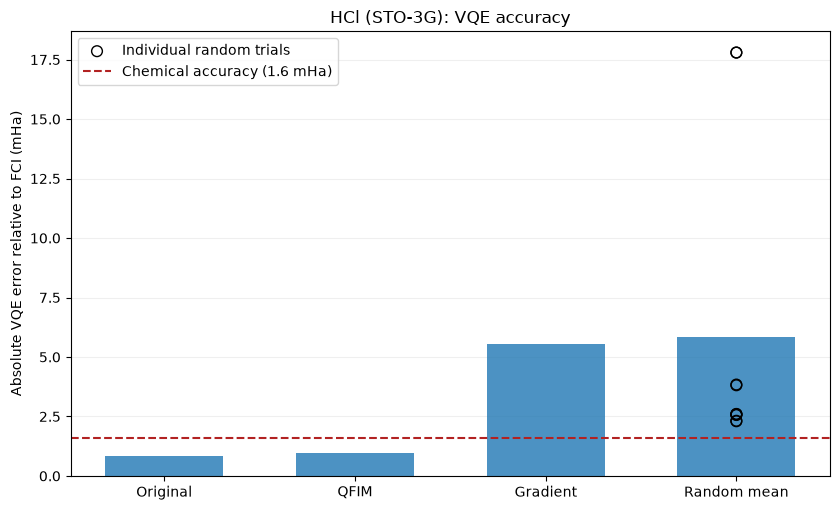

In [3]:
plot_rows = [
    ('QFIM', float(qfim['vqe_error_mha'])),
    ('Gradient', float(gradient['vqe_error_mha'])),
    ('Random mean', float(random_mean)),
]
if original is not None:
    plot_rows.insert(0, ('Original', float(original['vqe_error_mha'])))

labels, errors = zip(*plot_rows)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
x = np.arange(len(labels))
ax.bar(x, errors, alpha=0.8, width=0.62)
random_x = labels.index('Random mean')
ax.scatter(np.full(len(random_runs), random_x), random_runs['vqe_error_mha'],
           facecolors='none', edgecolors='black', s=60, zorder=4,
           label='Individual random trials')
ax.axhline(1.6, color='firebrick', linestyle='--', linewidth=1.5,
           label='Chemical accuracy (1.6 mHa)')
ax.set_xticks(x, labels)
ax.set_ylabel('Absolute VQE error relative to FCI (mHa)')
ax.set_title('HCl (STO-3G): VQE accuracy')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
fig.savefig('vqe_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

## Circuit resources

We use the same standardized gate set and transpilation settings for these circuit counts. Comparing the unpruned CS ansatz with QFIM pruning shows how many gates and layers are removed after the original contextual-subspace reduction [1, 2].

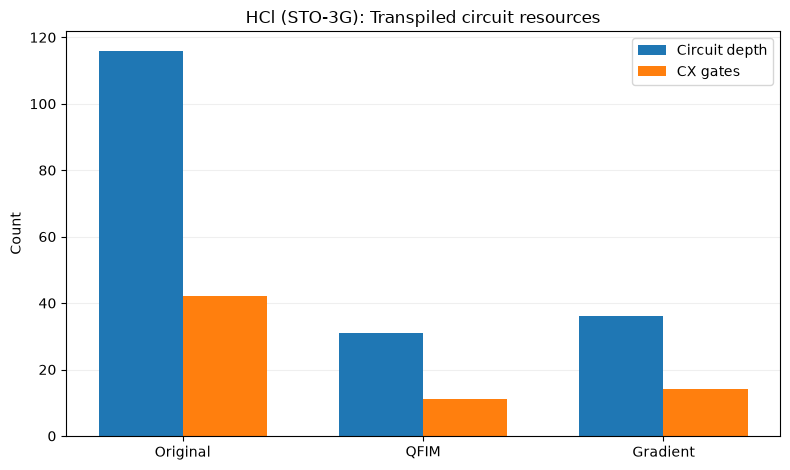

In [4]:
resource_runs = [('QFIM', qfim), ('Gradient', gradient)]
if original is not None:
    resource_runs.insert(0, ('Original', original))
labels_r = [name for name, _ in resource_runs]
depths = [float(row['depth']) for _, row in resource_runs]
cx_counts = [float(row['cx_gates']) for _, row in resource_runs]
x = np.arange(len(labels_r))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(x - width / 2, depths, width, label='Circuit depth')
ax.bar(x + width / 2, cx_counts, width, label='CX gates')
ax.set_xticks(x, labels_r)
ax.set_ylabel('Count')
ax.set_title('HCl (STO-3G): Transpiled circuit resources')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
fig.savefig('circuit_resources.png', dpi=300, bbox_inches='tight')
plt.show()

## Preliminary hardware comparison

We also tested the QFIM- and gradient-selected circuits on IBM Kingston, using their previously optimized statevector parameters and 1,024 shots each, without further optimization on hardware.

The QFIM circuit produced a VQE error of **117.776 mHa**, compared with **152.124 mHa** for gradient selection. This is consistent with our statevector results, where QFIM also achieves a lower energy error under the same four-operator constraint.

However, both hardware errors are substantially larger than their ideal-statevector counterparts. Since we only performed one hardware measurement per circuit, further trials would be needed to determine whether the observed difference is statistically significant.

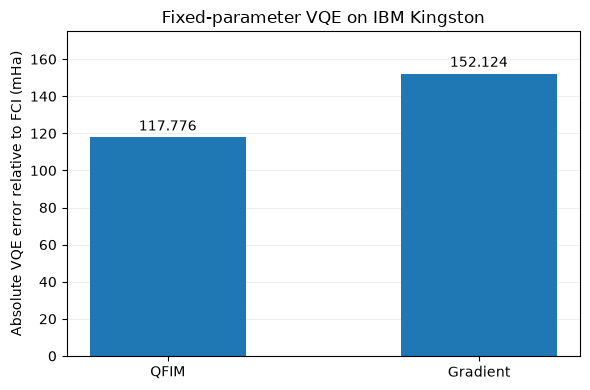

In [2]:
# Fixed-parameter hardware comparison (IBM Kingston, 1024 shots)
import matplotlib.pyplot as plt

methods = ["QFIM", "Gradient"]
errors = [117.776, 152.124]  # mHa relative to FCI

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(methods, errors, width=0.5)

for bar, error in zip(bars, errors):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        error + 2,
        f"{error:.3f}",
        ha="center",
        va="bottom"
    )

ax.set_ylabel("Absolute VQE error relative to FCI (mHa)")
ax.set_title("Fixed-parameter VQE on IBM Kingston")
ax.set_ylim(0, 175)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

## Interpretation and limitations

For HCl, QFIM-based selection retains **4 of 16 operators** (75% fewer parameters) while preserving chemical accuracy. Compared with the unpruned contextual ansatz, circuit depth decreases from **116 to 31** (73.3%) and CX gates from **42 to 11** (73.8%). The QFIM VQE error is **0.966 mHa**, compared with **5.555 mHa** for gradient selection and **5.821 mHa** on average across ten random subsets. Although the unpruned circuit is slightly more accurate at 0.843 mHa, our selected circuit achieves nearly the same energy with substantially fewer resources.

These results suggest that considering the geometry of the variational state can be more effective than ranking operators individually by their energy gradients. The four-operator ansatz comes within **0.129 mHa** of the exact contextual-subspace ground energy. Our method further compresses the three-qubit contextual circuit, although this does not establish an end-to-end runtime speedup, particularly given the cost of computing the QFIM.

Our ideal-statevector benchmarks use fixed optimization settings, while the preliminary hardware comparison evaluates both selected circuits using their statevector-optimized parameters. The hardware results are consistent with the simulation results, although repeated measurements would be needed to establish whether the difference is statistically significant. Testing other molecules and optimization initializations would also help determine how general this advantage is. We compare VQE energies rather than postprocessed energies, since our CS-only diagonalization is not the full fermionic SQD procedure.

## References

[1] K. Zheng, Y. Zhou, J. Cheng, Z. Zhang, S. Li, and Z. Liang, *SQD-Enabled Circuit Compression for Resource-Efficient Quantum Chemistry* (2026), arXiv:2607.15076, https://doi.org/10.48550/arXiv.2607.15076.

[2] K. Zheng et al., *CS-VQE-SQD source code*, https://github.com/zkysfls/cs-vqe-sqd. Original contextual Hamiltonian data, excitation-pool construction, gradient-ranking baseline, and SQD workflow.

[3] J. Stokes, J. Izaac, N. Killoran, and G. Carleo, *Quantum Natural Gradient*, **Quantum 4**, 269 (2020), https://doi.org/10.22331/q-2020-05-25-269.